In [1]:
import seaborn as sns
import matplotlib.pyplot as plt

from sklearn. model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier , plot_tree
from sklearn.metrics import (
accuracy_score ,
precision_score ,
recall_score ,
f1_score ,
classification_report ,
confusion_matrix
)

In [3]:
import pandas as pd
df = pd.read_csv('post.csv')

In [9]:
df.head()

,Years Experience,Employed,Previous Employers,Level of Education,Top-tier School,Interned,Hired
0,10,True,4,BS,N,N,Y
1,0,False,0,BS,Y,Y,Y
2,7,False,6,BS,N,N,N
3,2,True,1,MS,Y,N,Y
4,20,False,2,PhD,Y,N,N


In [10]:
df['Level of Education'].unique()

<StringArray>
['BS', 'MS', 'PhD']
Length: 3, dtype: str

In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 13 entries, 0 to 12
Data columns (total 7 columns):
 #   Column              Non-Null Count  Dtype
---  ------              --------------  -----
 0   Years Experience    13 non-null     int64
 1   Employed            13 non-null     str  
 2   Previous Employers  13 non-null     int64
 3   Level of Education  13 non-null     str  
 4   Top-tier School     13 non-null     str  
 5   Interned            13 non-null     str  
 6   Hired               13 non-null     str  
dtypes: int64(2), str(5)
memory usage: 860.0 bytes


In [7]:
df.describe()

,Years Experience,Previous Employers
count,13.000000,13.000000
mean,5.153846,1.769231
std,6.348834,2.006400
min,0.000000,0.000000
25%,0.000000,0.000000
50%,3.000000,1.000000
75%,7.000000,2.000000
max,20.000000,6.000000


<Axes: >

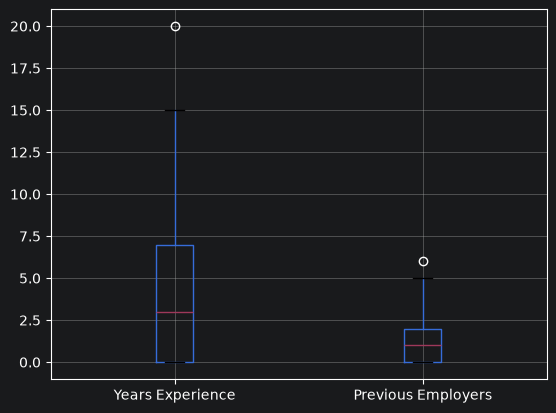

In [8]:
df.boxplot()

In [6]:
df.columns

Index(['Years Experience', 'Employed', 'Previous Employers',
       'Level of Education', 'Top-tier School', 'Interned', 'Hired'],
      dtype='str')

In [12]:
df.columns[-1]

'Hired'

In [16]:
cat = df.select_dtypes(exclude =["number"]).columns
num = df.select_dtypes(include =["number"]).columns

In [20]:
for col in cat :
    df[col] = df[col].astype("category").cat.codes

In [22]:
print(df.head ())
print(df.dtypes)


   Years Experience  Employed  Previous Employers  Level of Education  \
0                10         1                   4                   0   
1                 0         0                   0                   0   
2                 7         0                   6                   0   
3                 2         1                   1                   1   
4                20         0                   2                   2   

   Top-tier School  Interned  Hired  
0                0         0      1  
1                1         1      1  
2                0         0      0  
3                1         0      1  
4                1         0      0  
Years Experience      int64
Employed               int8
Previous Employers    int64
Level of Education     int8
Top-tier School        int8
Interned               int8
Hired                  int8
dtype: object


In [25]:
#preparation des donne
X = df.iloc[:,:-1]
y = df.iloc[:,-1]

X_train, X_test , y_train, y_test = train_test_split(
    X,
    y,
    test_size = 0.2,
    stratify = y,
    random_state = 42
)

In [27]:
print("X_train :", X_train.shape)
print("X_test :", X_test.shape)
print("y_train :", y_train.shape)
print("y_test :", y_test.shape)

X_train : (10, 6)
X_test : (3, 6)
y_train : (10,)
y_test : (3,)


In [36]:
from sklearn.tree import DecisionTreeClassifier,plot_tree
clf = DecisionTreeClassifier(

)
clf.fit(X_train,y_train)
y_pred = clf.predict(X_test)

accuracy = accuracy_score (y_test , y_pred)
precision = precision_score (
y_test , y_pred , average="weighted")
recall = recall_score (
y_test , y_pred , average="weighted")
f1 = f1_score(
y_test , y_pred , average="weighted")

print("Accuracy :", accuracy)
print("Precision :", precision )
print("Recall :", recall)
print("F1-score :", f1)

Accuracy : 0.6666666666666666
Precision : 0.4444444444444444
Recall : 0.6666666666666666
F1-score : 0.5333333333333333


C:\Users\user\PycharmProjects\Tp_AI_1\.venv\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])


In [37]:
print('repport de classification :')
print(classification_report (y_test , y_pred))

repport de classification :
              precision    recall  f1-score   support

           0       0.00      0.00      0.00         1
           1       0.67      1.00      0.80         2

    accuracy                           0.67         3
   macro avg       0.33      0.50      0.40         3
weighted avg       0.44      0.67      0.53         3



C:\Users\user\PycharmProjects\Tp_AI_1\.venv\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
C:\Users\user\PycharmProjects\Tp_AI_1\.venv\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
C:\Users\user\PycharmProjects\Tp_AI_1\.venv\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capital

Matrice de confusion :\n [[0 1]
 [0 2]]


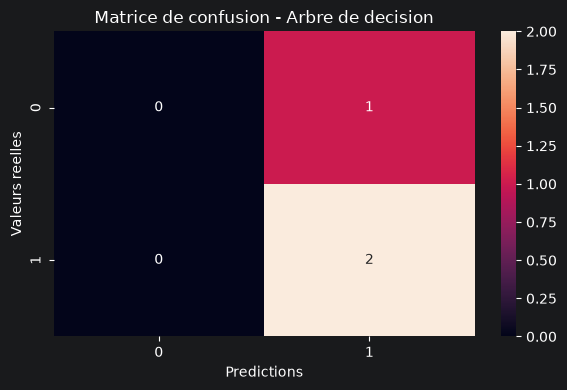

In [38]:
cm = confusion_matrix (y_test , y_pred)
print("Matrice de confusion :\\n", cm)
plt.figure(figsize =(6, 4))
sns.heatmap(cm , annot=True , fmt="d")
plt.xlabel("Predictions")
plt.ylabel("Valeurs reelles")
plt.title("Matrice de confusion - Arbre de decision")
plt. tight_layout ()
plt.show ()

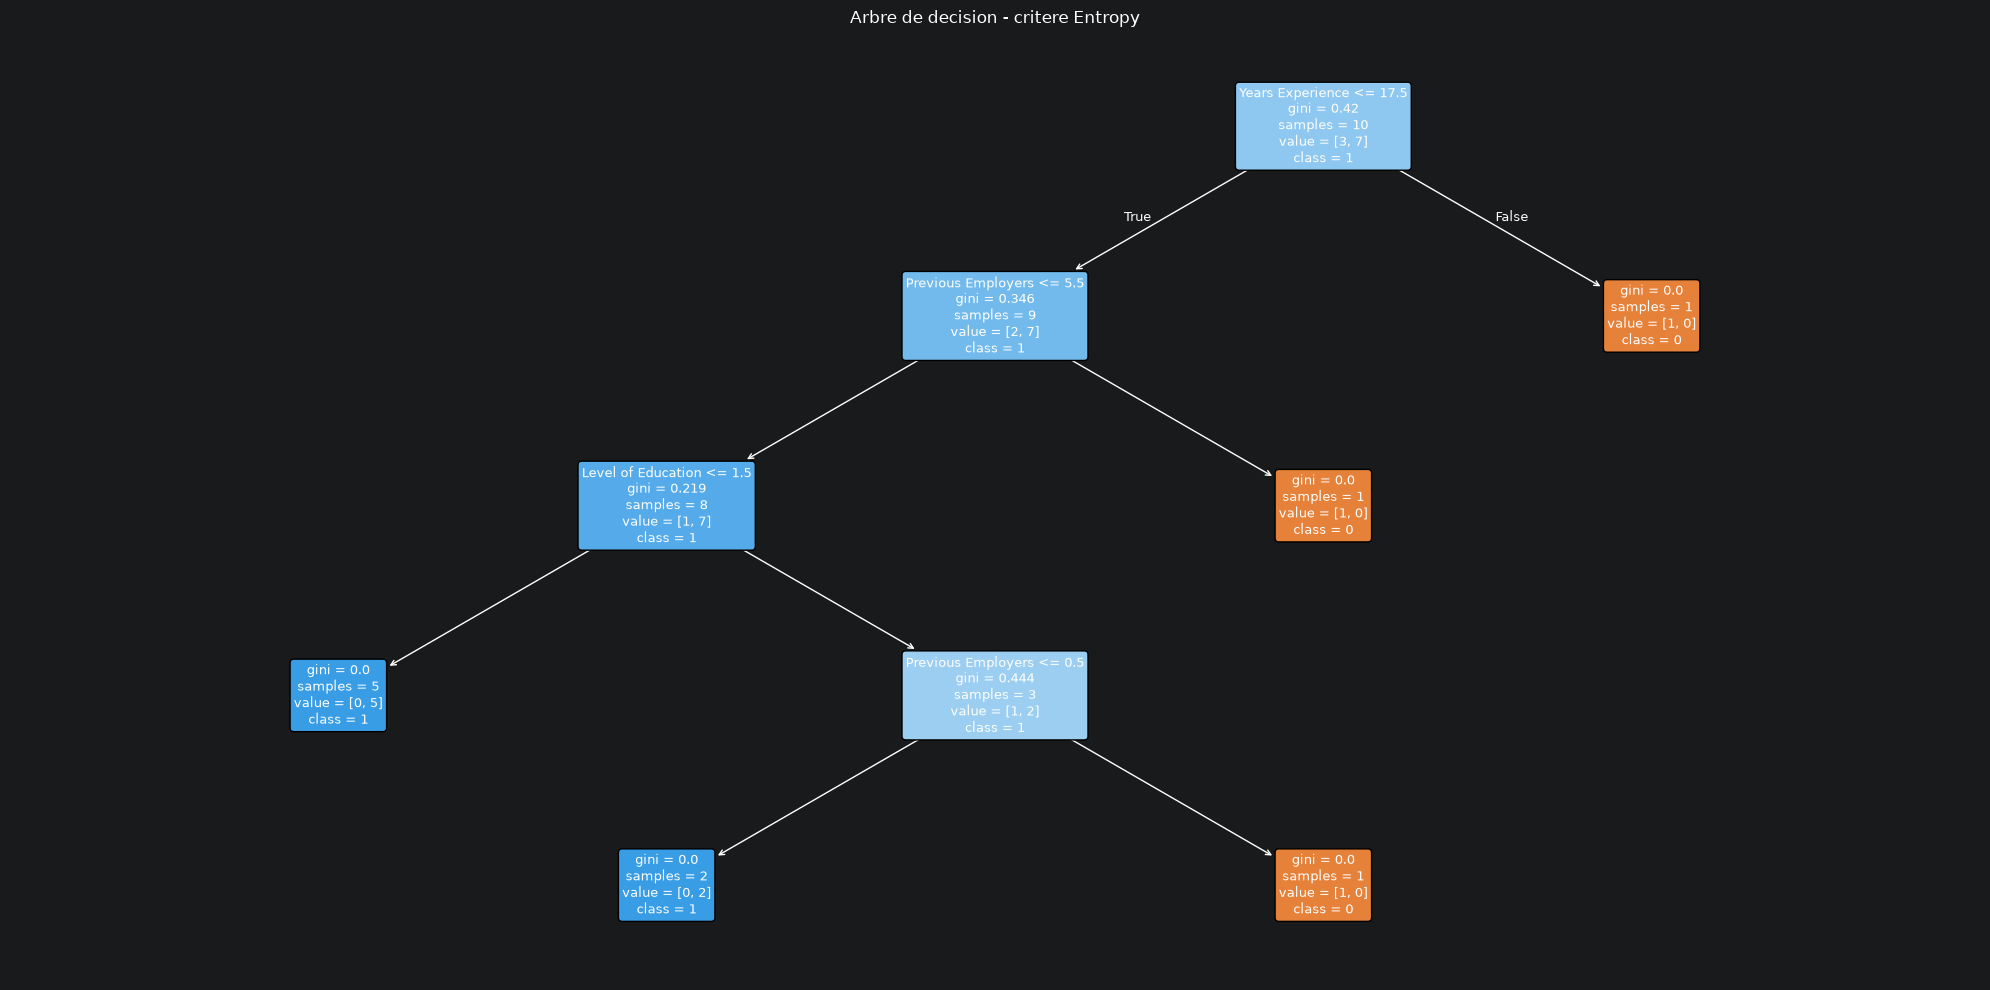

In [44]:
# Visualisation directe avec scikit -learn
plt.figure(figsize =(20 , 10))
plot_tree (
     clf ,
     feature_names =X.columns ,
     class_names =[str(c) for c in clf.classes_],
     filled=True ,
     rounded=True ,
     fontsize =9
 )

plt.title("Arbre de decision - critere Entropy")
plt.tight_layout()
plt.show()

In [47]:
root_feature_index = clf.tree_.feature [0]
root_feature_name = X.columns[ root_feature_index ]
print("Variable a la racine :", root_feature_name )

Variable a la racine : Years Experience


In [57]:
criteria = {'gini', 'entropy'}
criterion_scores = {}
criterion_models = {}

In [59]:
for c in criteria:
    tree_model = DecisionTreeClassifier(
        criterion=c
        max_depth=3,random_state=24
    )
    tree_model.fit(X_train,y_train)
    y_pred = tree_model.predict(X_test)
    accuracy = accuracy_score (y_test , y_pred)
    precision = precision_score (y_test , y_pred, average="weighted")
    criterion_scores [ c ] = accuracy
    criterion_models [ c ] = tree_model

C:\Users\user\PycharmProjects\Tp_AI_1\.venv\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
C:\Users\user\PycharmProjects\Tp_AI_1\.venv\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])


In [60]:
for criterion , tree_model in criterion_models .items ():
    index_racine = tree_model .tree_.feature [0]
    variable_racine = X.columns[ index_racine ]
    print(criterion , "-> racine :", variable_racine)

gini -> racine : Previous Employers
entropy -> racine : Previous Employers
